### This is our workflow , where a model screens a DR effected eye and logs a report with gradCAM heatmap analysis , model used = EFficientNet **B4**

**Mounting google DRIVE = [RUN]**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **checking GPU device** [RUN]

In [ ]:
# Check GPU
import torch
print("GPU Available:", torch.cuda.is_available())
print("GPU Name:", torch.cuda.get_device_name(0))

# Project paths
PROJECT_PATH = "/content/drive/MyDrive/DR_Project"
DATASET_PATH = f"{PROJECT_PATH}/dataset"
MODEL_PATH = f"{PROJECT_PATH}/models"
OUTPUT_PATH = f"{PROJECT_PATH}/outputs"

import os

os.makedirs(DATASET_PATH, exist_ok=True)
os.makedirs(MODEL_PATH, exist_ok=True)
os.makedirs(OUTPUT_PATH, exist_ok=True)

GPU Available: True
GPU Name: Tesla T4


**installing dependent libraries** [RUN]


In [ ]:
!pip install -q efficientnet_pytorch
!pip install -q albumentations
!pip install -q grad-cam
!pip install -q opencv-python
!pip install -q kaggle

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 99.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


# **Downloading Dataset from kaggle hub** [DO NOT RUN]

In [ ]:
import kagglehub

path = kagglehub.dataset_download("mariaherrerot/aptos2019")

print("Dataset path:", path)

import shutil

SOURCE_PATH = path
DEST_PATH = "/content/drive/MyDrive/DR_Project/dataset"

shutil.copytree(SOURCE_PATH, DEST_PATH, dirs_exist_ok=True)

print("Dataset successfully copied!")

 27%|██▋       | 2.15G/8.01G [00:12<00:35, 179MB/s]


KeyboardInterrupt: 

checking list of cotnets in dataset [RUN / DONT RUN = does'nt matter]

In [ ]:
!ls -R /content/drive/MyDrive/DR_Project/dataset

/content/drive/MyDrive/DR_Project/dataset:
test.csv  test_images  train_1.csv  train_images  valid.csv  val_images

/content/drive/MyDrive/DR_Project/dataset/test_images:
test_images

/content/drive/MyDrive/DR_Project/dataset/test_images/test_images:
e4dcca36ceb4.png  eadfc8809ec8.png  f2094a20b275.png  f901d460517c.png
e4e343eaae2a.png  eae70f527755.png  f233638e0e90.png  f90f8931a9bc.png
e4f12411fd85.png  eae901557a84.png  f23902998c21.png  f9156aeffc5e.png
e50b0174690d.png  eb050765b323.png  f252046c0fe6.png  f91cfa82b9d4.png
e5197d77ec68.png  eb175669d789.png  f26b02ead915.png  f920ccd926db.png
e529c5757d64.png  eb1ad14dd281.png  f298b7d05958.png  f952ad2e4356.png
e52ed5c29c5e.png  eb1d37b71fd1.png  f2c0b41acd05.png  f994a3b07935.png
e540d2e35d15.png  eb32a815f78c.png  f2d2a0c92034.png  f999c6921e6d.png
e55188915f9d.png  eb6b1f1c09db.png  f2ee81781411.png  f9aa35187bf3.png
e580676516b0.png  eba3acc42197.png  f2f569a64949.png  f9d52509c571.png
e582e56e7942.png  ebd96d853918.png  f30

**creating paths** [**RUN**]

In [ ]:
DATASET_PATH = "/content/drive/MyDrive/DR_Project/dataset"

TRAIN_CSV = f"{DATASET_PATH}/train_1.csv"
VAL_CSV   = f"{DATASET_PATH}/valid.csv"

TRAIN_IMG_PATH = f"{DATASET_PATH}/train_images/train_images"
VAL_IMG_PATH   = f"{DATASET_PATH}/val_images/val_images"

print(TRAIN_IMG_PATH)
print(VAL_IMG_PATH)

/content/drive/MyDrive/DR_Project/dataset/train_images/train_images
/content/drive/MyDrive/DR_Project/dataset/val_images/val_images


checking the train and test sizes from the dataset [**RUN**]

In [ ]:
import pandas as pd

train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)

print(train_df.head())
print("Train size:", len(train_df))
print("Val size:", len(val_df))

        id_code  diagnosis
0  1ae8c165fd53          2
1  1b329a127307          1
2  1b32e1d775ea          4
3  1b3647865779          0
4  1b398c0494d1          0
Train size: 2930
Val size: 366


**getting a numpy array of preprocessed sample [safe to RUN]**

In [ ]:
import cv2
import numpy as np

def preprocess_image(path, size=512):

    img = cv2.imread(path)

    if img is None:
        raise Exception(f"Image not found: {path}")

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    img = cv2.resize(img, (size, size))

    # Graham preprocessing
    img = cv2.addWeighted(
        img,
        4,
        cv2.GaussianBlur(img, (0,0), size/30),
        -4,
        128
    )

    # CLAHE
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l,a,b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=3.0,
        tileGridSize=(8,8)
    )

    cl = clahe.apply(l)

    merged = cv2.merge((cl,a,b))

    img = cv2.cvtColor(merged, cv2.COLOR_LAB2RGB)

    img = img / 255.0



    return img.astype(np.float32)

print( preprocess_image(f'{TRAIN_IMG_PATH}/1ae8c165fd53.png'))




[[[0.5568628  0.5372549  0.5176471 ]
  [0.5647059  0.5529412  0.54901963]
  [0.5647059  0.5529412  0.54901963]
  ...
  [0.74509805 0.73333335 0.7294118 ]
  [0.74509805 0.73333335 0.7294118 ]
  [0.7372549  0.7137255  0.69803923]]

 [[0.5294118  0.5019608  0.5019608 ]
  [0.5647059  0.5529412  0.54901963]
  [0.5647059  0.5529412  0.54901963]
  ...
  [0.74509805 0.73333335 0.7294118 ]
  [0.74509805 0.73333335 0.7294118 ]
  [0.7176471  0.6862745  0.6862745 ]]

 [[0.5647059  0.5529412  0.54901963]
  [0.5058824  0.4862745  0.49019608]
  [0.5058824  0.4862745  0.49019608]
  ...
  [0.7607843  0.7294118  0.7294118 ]
  [0.74509805 0.73333335 0.7294118 ]
  [0.74509805 0.73333335 0.7294118 ]]

 ...

 [[0.49019608 0.5058824  0.5019608 ]
  [0.49019608 0.5058824  0.5019608 ]
  [0.49019608 0.5058824  0.5019608 ]
  ...
  [0.60784316 0.627451   0.62352943]
  [0.60784316 0.627451   0.62352943]
  [0.60784316 0.627451   0.62352943]]

 [[0.49019608 0.5058824  0.5019608 ]
  [0.49019608 0.5058824  0.5019608 ]


**testing for pre-processed image outputs** [SAFE TO RUN]

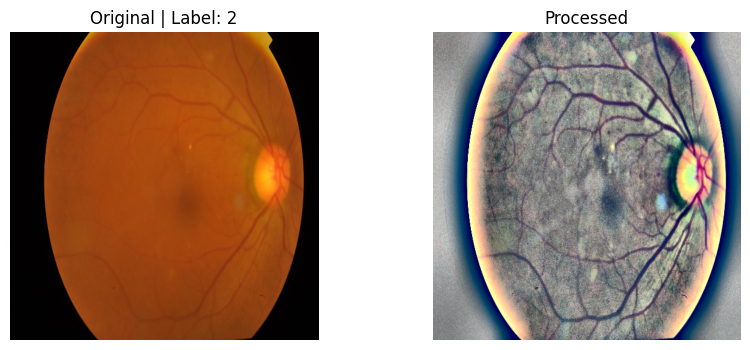

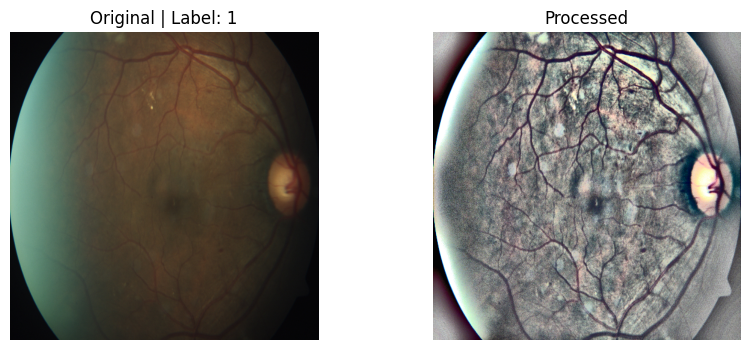

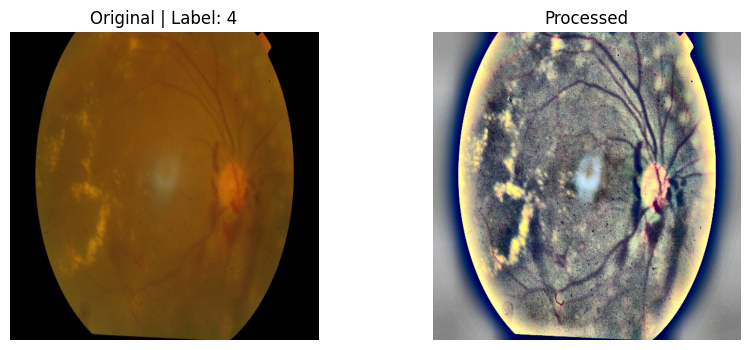

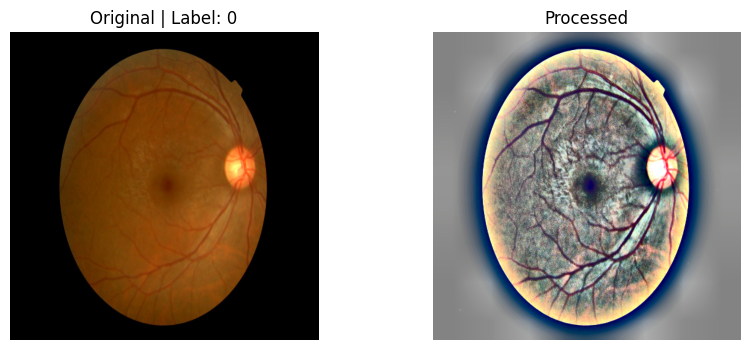

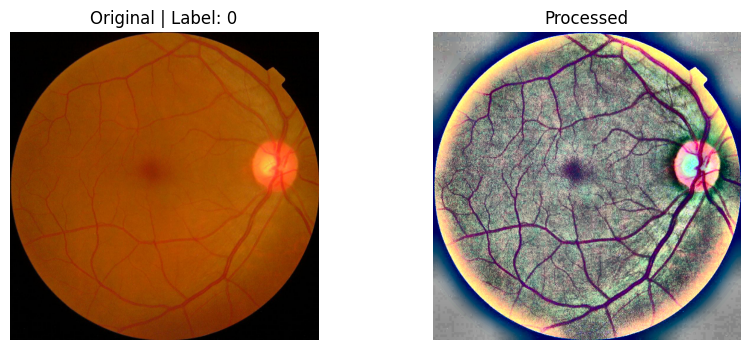

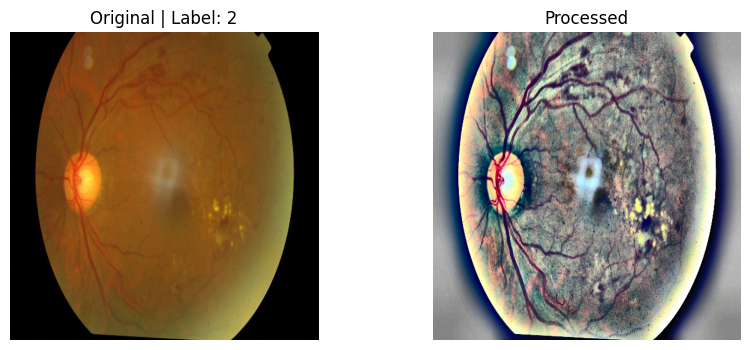

In [ ]:
import matplotlib.pyplot as plt
import cv2

for i in range(6):

    img_id = train_df.iloc[i]["id_code"]
    label = train_df.iloc[i]["diagnosis"]

    path = f"{TRAIN_IMG_PATH}/{img_id}.png"

    original = cv2.imread(path)
    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    original = cv2.resize(original, (512,512))

    processed = preprocess_image(path)

    plt.figure(figsize=(10,4))

    plt.subplot(1,2,1)
    plt.imshow(original)
    plt.title(f"Original | Label: {label}")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(processed)
    plt.title("Processed")
    plt.axis("off")

    plt.show()

# **reading CSV files** [SAFE TO RUN]

In [ ]:
train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)

train_df["label"] = train_df["diagnosis"].astype(int)
val_df["label"]   = val_df["diagnosis"].astype(int)

print(train_df.columns)
print(sorted(train_df["label"].unique()))

Index(['id_code', 'diagnosis', 'label'], dtype='object')
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


# **setting up labels[0->4] for  severity** [SAFE TO RUN]

In [ ]:
train_df["label"] = train_df["diagnosis"].astype(int)
val_df["label"]   = val_df["diagnosis"].astype(int)

print("Label column recreated")
print(sorted(train_df["label"].unique()))

Label column recreated
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


# NOW CONNECTING CSV FILES TO IMG_PATH to load all images and feed it to preprocessing [safe to run]


In [ ]:
import os
import torch
from torch.utils.data import Dataset

class DRDataset(Dataset):

    def __init__(self, df, img_dir):

        self.img_dir = img_dir

        # Keep only rows where image exists
        self.df = df[df['id_code'].apply(
            lambda x: os.path.exists(f"{img_dir}/{x}.png")
        )].reset_index(drop=True)

        print(f"Valid images found: {len(self.df)}")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        img_path = f"{self.img_dir}/{row['id_code']}.png"

        try:
            image = preprocess_image(img_path)
        except:
            # If somehow still fails, return a random valid sample instead
            return self.__getitem__((idx + 1) % len(self.df))

        image = torch.tensor(image).permute(2,0,1).float()
        label = torch.tensor(int(row["label"]), dtype=torch.long)

        return image, label

# DATA LOADER => LOOP HTORUGH ALL THE IMAGES [RUN]

In [ ]:
import os

print("TRAIN_IMG_PATH:", TRAIN_IMG_PATH)

print("\nSample files in folder:")
print(os.listdir(TRAIN_IMG_PATH)[:10])

TRAIN_IMG_PATH: /content/drive/MyDrive/DR_Project/dataset/train_images/train_images

Sample files in folder:
['683023cda6a5.png', '79059d0592c4.png', '1eee55494271.png', 'b35cad8fe2d7.png', '5b3e7197ac1c.png', '4ab8c0cece7f.png', '5a11d21c2828.png', '6d3d1fe6c32a.png', 'a14bbd9a583e.png', '8dba09a4e5ed.png']


**RUN [for no of images]**

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

train_dataset = DRDataset(train_df, TRAIN_IMG_PATH)
val_dataset   = DRDataset(val_df, VAL_IMG_PATH)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=0)

Valid images found: 2930
Valid images found: 366


**checking random label counts for every image loaded** [safe to run]

In [ ]:
images, labels = next(iter(train_loader))

print("Labels min:", labels.min().item())
print("Labels max:", labels.max().item())

Labels min: 0
Labels max: 3


# Load EfficientNet-**B4** = > [RUN!]

In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [ ]:
!pip install efficientnet_pytorch

In [ ]:
from efficientnet_pytorch import EfficientNet
import torch.nn as nn

model = EfficientNet.from_pretrained('efficientnet-b4')

model._fc = nn.Sequential(
    nn.Linear(1792, 512),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(512, 5)
)

model = model.to(device)

print(sorted(train_df["label"].unique()))

Downloading: "https://github.com/lukemelas/EfficientNet-PyTorch/releases/download/1.0/efficientnet-b4-6ed6700e.pth" to /root/.cache/torch/hub/checkpoints/efficientnet-b4-6ed6700e.pth


100%|██████████| 74.4M/74.4M [00:02<00:00, 39.0MB/s]


Loaded pretrained weights for efficientnet-b4
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


# **LOSS +** **OPTIMIZER** [run]

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

from torch.amp import GradScaler, autocast

scaler = GradScaler(device='cuda')

**checking label count => confirmation**

In [ ]:
images, labels = next(iter(train_loader))

print("Labels min:", labels.min().item())
print("Labels max:", labels.max().item())

Labels min: 0
Labels max: 4


# **TRAINING LOOP**

In [ ]:
from torch.amp import GradScaler, autocast
from tqdm import tqdm
import torch

scaler = GradScaler(device='cuda')

EPOCHS = 10
best_val_acc = 0

for epoch in range(4,EPOCHS):

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print("-"*40)

    # -------------------
    # TRAINING
    # -------------------
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        with autocast(device_type='cuda'):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    train_acc = 100 * train_correct / train_total
    train_loss /= len(train_loader)

    # -------------------
    # VALIDATION
    # -------------------
    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_acc = 100 * val_correct / val_total

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2f}%")
    print(f"Validation Accuracy: {val_acc:.2f}%")

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(
            model.state_dict(),
            "/content/drive/MyDrive/DR_Project/models/best_dr_model.pth"
        )
        print("Best model saved 🔥")


Epoch 5/10
----------------------------------------


100%|██████████| 367/367 [11:38<00:00,  1.90s/it]


Train Loss: 0.7803
Train Accuracy: 73.14%
Validation Accuracy: 78.69%
Best model saved 🔥

Epoch 6/10
----------------------------------------


100%|██████████| 367/367 [10:41<00:00,  1.75s/it]


Train Loss: 0.5365
Train Accuracy: 79.11%
Validation Accuracy: 82.51%
Best model saved 🔥

Epoch 7/10
----------------------------------------


100%|██████████| 367/367 [10:41<00:00,  1.75s/it]


... (3 outputs left out)

100%|██████████| 367/367 [10:38<00:00,  1.74s/it]


Train Loss: 0.2366
Train Accuracy: 92.08%
Validation Accuracy: 85.79%
Best model saved 🔥

Epoch 10/10
----------------------------------------


100%|██████████| 367/367 [10:39<00:00,  1.74s/it]


Train Loss: 0.1683
Train Accuracy: 94.78%
Validation Accuracy: 83.06%


# **Loading the TRained model**

In [ ]:
import torch
from efficientnet_pytorch import EfficientNet
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Recreate model architecture
model = EfficientNet.from_pretrained('efficientnet-b4')

model._fc = nn.Sequential(
    nn.Linear(1792, 512),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(512, 5)
)

model = model.to(device)

# Load saved weights
checkpoint_path = "/content/drive/MyDrive/DR_Project/models/best_dr_model.pth"

model.load_state_dict(torch.load(checkpoint_path, map_location=device))

model.eval()

print("Model loaded successfully")

Loaded pretrained weights for efficientnet-b4
Model loaded successfully


# installing gradCAM **library**

In [ ]:
!pip install grad-cam

# **GradCAM mapping and result comaprision**

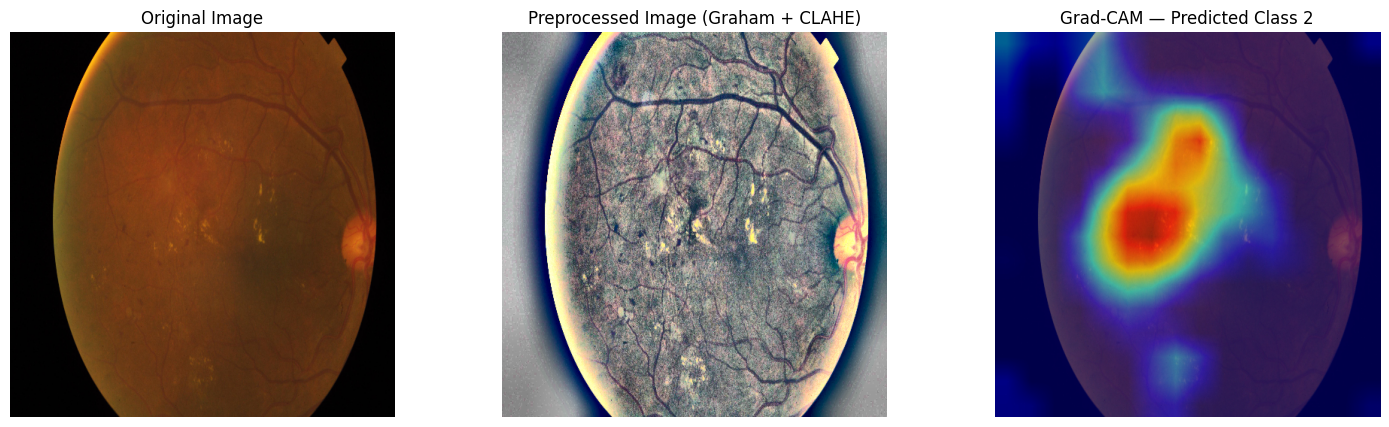

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Select target layer
target_layer = model._blocks[-1]

cam = GradCAM(
    model=model,
    target_layers=[target_layer]
)

# Choose a test image
img_path = f"{VAL_IMG_PATH}/{val_df.iloc[0]['id_code']}.png"

# Preprocess image
original_img = cv2.imread(img_path)
original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
original_img = cv2.resize(original_img, (512,512))

input_img = preprocess_image(img_path)
input_tensor = torch.tensor(input_img).permute(2,0,1).unsqueeze(0).to(device)

# Get prediction
outputs = model(input_tensor)
pred_class = torch.argmax(outputs).item()

# Generate Grad-CAM
grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=[ClassifierOutputTarget(pred_class)]
)

grayscale_cam = grayscale_cam[0]

# Overlay heatmap
visualization = show_cam_on_image(
    original_img.astype(np.float32)/255.0,
    grayscale_cam,
    use_rgb=True
)

# Generate preprocessed image (for display)
preprocessed_img = preprocess_image(img_path)

plt.figure(figsize=(18,5))

# Original Image
plt.subplot(1,3,1)
plt.title("Original Image")
plt.imshow(original_img)
plt.axis('off')

# Preprocessed Image
plt.subplot(1,3,2)
plt.title("Preprocessed Image (Graham + CLAHE)")
plt.imshow(preprocessed_img)
plt.axis('off')

# Grad-CAM Image
plt.subplot(1,3,3)
plt.title(f"Grad-CAM — Predicted Class {pred_class}")
plt.imshow(visualization)
plt.axis('off')

plt.show()


In [ ]:
REPORT_DIR = "/content/drive/MyDrive/DR_Project/outputs/reports"
GRADCAM_DIR = "/content/drive/MyDrive/DR_Project/outputs/gradcam"

os.makedirs(REPORT_DIR, exist_ok=True)
os.makedirs(GRADCAM_DIR, exist_ok=True)

print("Folders ready")

Folders ready


In [ ]:
class_info = {

    0: {
        "name": "No Diabetic Retinopathy",
        "severity_score": 0,
        "action": "No immediate action required. Annual screening recommended."
    },

    1: {
        "name": "Mild Diabetic Retinopathy",
        "severity_score": 1,
        "action": "Monitor condition. Follow-up screening in 6–12 months."
    },

    2: {
        "name": "Moderate Diabetic Retinopathy",
        "severity_score": 2,
        "action": "Ophthalmologist referral recommended. Possible early treatment."
    },

    3: {
        "name": "Severe Diabetic Retinopathy",
        "severity_score": 3,
        "action": "Urgent ophthalmologist evaluation required."
    },

    4: {
        "name": "Proliferative Diabetic Retinopathy",
        "severity_score": 4,
        "action": "Immediate specialist treatment required. High risk of vision loss."
    }
}

# **# APPLYING GRADCAM FOR A BATCH OF IMAGES**

In [ ]:
NUM_IMAGES = 25

df_source = val_df.sample(NUM_IMAGES, random_state=42)

target_layer = model._blocks[-1]

cam = GradCAM(model=model, target_layers=[target_layer])

for idx, row in df_source.iterrows():

    img_id = row['id_code']
    img_path = f"{VAL_IMG_PATH}/{img_id}.png"

    if not os.path.exists(img_path):
        continue

    # Load images
    original = cv2.imread(img_path)
    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    original = cv2.resize(original, (512,512))

    preprocessed = preprocess_image(img_path)

    input_tensor = torch.tensor(preprocessed).permute(2,0,1).unsqueeze(0).to(device)

    # Prediction
    with torch.no_grad():

        outputs = model(input_tensor)

        probs = torch.softmax(outputs, dim=1)

        pred_class = torch.argmax(probs).item()

        confidence = probs[0][pred_class].item()

    info = class_info[pred_class]

    severity_score = info["severity_score"]
    severity_level = info["name"]
    suggested_action = info["action"]

    # GradCAM
    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=[ClassifierOutputTarget(pred_class)]
    )[0]

    gradcam_img = show_cam_on_image(
        original.astype(np.float32)/255.0,
        grayscale_cam,
        use_rgb=True
    )

    # Save GradCAM image
    gradcam_path = f"{GRADCAM_DIR}/{img_id}_gradcam.png"

    plt.figure(figsize=(12,4))

    plt.subplot(1,3,1)
    plt.imshow(original)
    plt.title("Original")
    plt.axis('off')

    plt.subplot(1,3,2)
    plt.imshow(preprocessed)
    plt.title("Preprocessed")
    plt.axis('off')

    plt.subplot(1,3,3)
    plt.imshow(gradcam_img)
    plt.title(f"{severity_level}\nConf: {confidence:.2f}")
    plt.axis('off')

    plt.tight_layout()
    plt.savefig(gradcam_path, dpi=150)
    plt.close()

    # Generate report
    report = f"""
Diabetic Retinopathy Screening Report
=====================================

Image ID: {img_id}

Predicted Severity Level: {severity_level}

Severity Score: {severity_score} / 4

Confidence Score: {confidence:.4f}

Suggested Clinical Action:
{suggested_action}

Model: EfficientNet-B4
Explainability: Grad-CAM heatmap generated

-------------------------------------
"""

    report_path = f"{REPORT_DIR}/{img_id}_report.txt"

    with open(report_path, "w") as f:
        f.write(report)

    print(f"Saved GradCAM: {gradcam_path}")
    print(f"Saved Report: {report_path}")
    print("--------------")

Saved GradCAM: /content/drive/MyDrive/DR_Project/outputs/gradcam/0e3572b5884a_gradcam.png
Saved Report: /content/drive/MyDrive/DR_Project/outputs/reports/0e3572b5884a_report.txt
--------------
Saved GradCAM: /content/drive/MyDrive/DR_Project/outputs/gradcam/025a169a0bb0_gradcam.png
Saved Report: /content/drive/MyDrive/DR_Project/outputs/reports/025a169a0bb0_report.txt
--------------
Saved GradCAM: /content/drive/MyDrive/DR_Project/outputs/gradcam/0125fbd2e791_gradcam.png
Saved Report: /content/drive/MyDrive/DR_Project/outputs/reports/0125fbd2e791_report.txt
--------------
Saved GradCAM: /content/drive/MyDrive/DR_Project/outputs/gradcam/1782142e17d9_gradcam.png
Saved Report: /content/drive/MyDrive/DR_Project/outputs/reports/1782142e17d9_report.txt
--------------
Saved GradCAM: /content/drive/MyDrive/DR_Project/outputs/gradcam/04579e31e4be_gradcam.png
Saved Report: /content/drive/MyDrive/DR_Project/outputs/reports/04579e31e4be_report.txt
--------------
Saved GradCAM: /content/drive/MyDri

In [ ]:
!pip install reportlab

In [ ]:
from google.colab import files

uploaded = files.upload()

uploaded_filename = list(uploaded.keys())[0]

print("Uploaded:", uploaded_filename)

In [ ]:
!pip install opencv-python

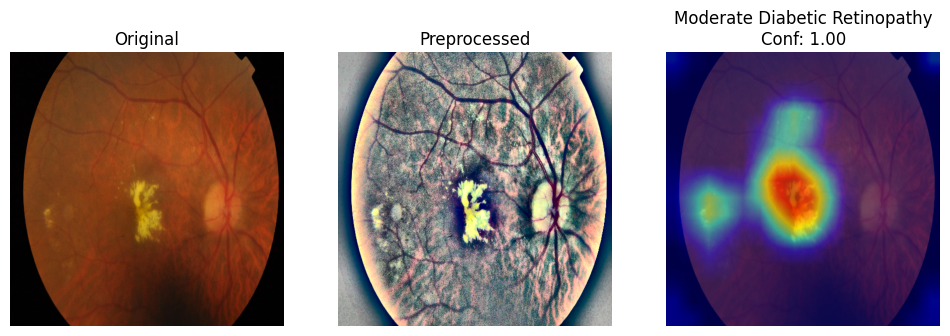

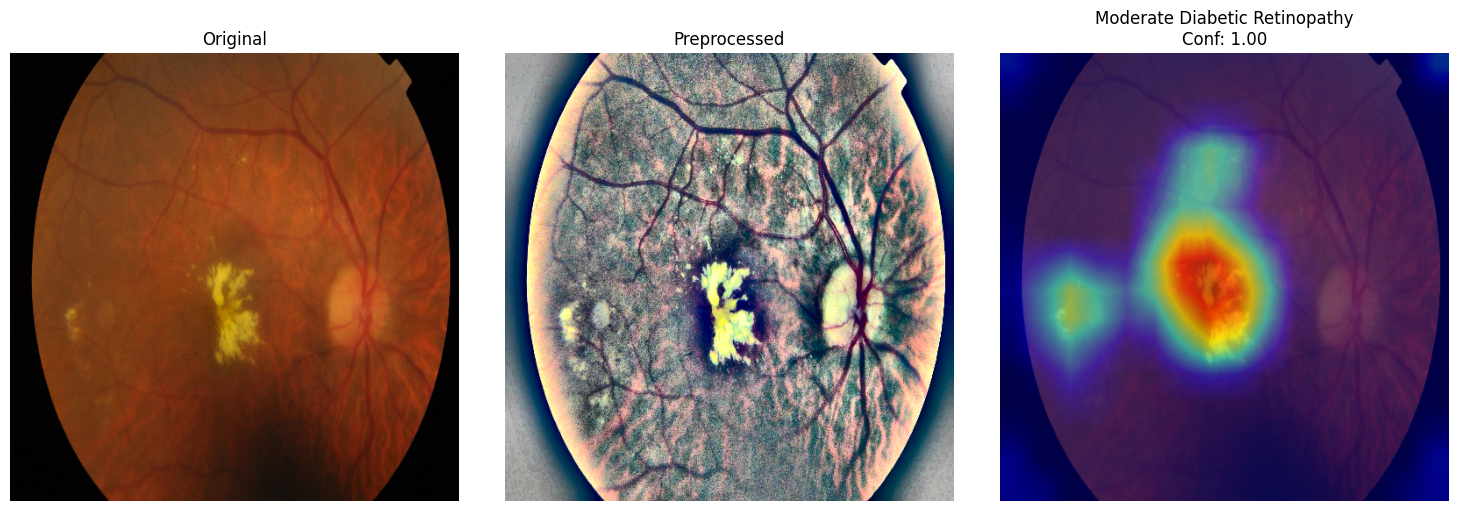

GradCAM image saved: /content/drive/MyDrive/DR_Project/outputs/user_uploads/gradcam_visualization.png
PDF report generated: /content/drive/MyDrive/DR_Project/outputs/user_uploads/DR_Report.pdf
GradCAM image saved
PDF report generated: /content/drive/MyDrive/DR_Project/outputs/user_uploads/DR_Report.pdf


In [ ]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

from reportlab.lib.pagesizes import letter
from reportlab.pdfgen import canvas
from reportlab.lib.units import inch

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Output paths
OUTPUT_DIR = "/content/drive/MyDrive/DR_Project/outputs/user_uploads"
os.makedirs(OUTPUT_DIR, exist_ok=True)

img_path = uploaded_filename

# Load original image
original = cv2.imread(img_path)
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
original = cv2.resize(original, (512,512))

# Preprocess
preprocessed = preprocess_image(img_path)

input_tensor = torch.tensor(preprocessed).permute(2,0,1).unsqueeze(0).to(device)

# Prediction
with torch.no_grad():

    outputs = model(input_tensor)

    probs = torch.softmax(outputs, dim=1)

    pred_class = torch.argmax(probs).item()

    confidence = probs[0][pred_class].item()

info = class_info[pred_class]

severity_score = info["severity_score"]
severity_level = info["name"]
suggested_action = info["action"]

# GradCAM
target_layer = model._blocks[-1]

cam = GradCAM(model=model, target_layers=[target_layer])

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=[ClassifierOutputTarget(pred_class)]
)[0]

gradcam_img = show_cam_on_image(
    original.astype(np.float32)/255.0,
    grayscale_cam,
    use_rgb=True
)

# Save visualization image
vis_path = f"{OUTPUT_DIR}/gradcam_result.png"

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(original)
plt.title("Original")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(preprocessed)
plt.title("Preprocessed")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(gradcam_img)
plt.title(f"{severity_level}\nConf: {confidence:.2f}")
plt.axis('off')

import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import shutil

from reportlab.lib.pagesizes import letter
from reportlab.pdfgen import canvas

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


# Output paths
OUTPUT_DIR = "/content/drive/MyDrive/DR_Project/outputs/user_uploads"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# Always copy uploaded file to permanent safe location
original_path = f"{OUTPUT_DIR}/uploaded_original.png"
shutil.copy(uploaded_filename, original_path)


# Visualization output path
vis_path = f"{OUTPUT_DIR}/gradcam_visualization.png"


# Load original image safely
original = cv2.imread(original_path)
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
original = cv2.resize(original, (512,512))


# Preprocess ONLY original image
preprocessed = preprocess_image(original_path)


# Model input
input_tensor = torch.tensor(preprocessed).permute(2,0,1).unsqueeze(0).to(device)


# Prediction
with torch.no_grad():

    outputs = model(input_tensor)

    probs = torch.softmax(outputs, dim=1)

    pred_class = torch.argmax(probs).item()

    confidence = probs[0][pred_class].item()


info = class_info[pred_class]

severity_score = info["severity_score"]
severity_level = info["name"]
suggested_action = info["action"]


# GradCAM from ORIGINAL image
target_layer = model._blocks[-1]

cam = GradCAM(model=model, target_layers=[target_layer])

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=[ClassifierOutputTarget(pred_class)]
)[0]


gradcam_img = show_cam_on_image(
    original.astype(np.float32)/255.0,
    grayscale_cam,
    use_rgb=True
)


# Create clean visualization
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(original)
plt.title("Original")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(preprocessed)
plt.title("Preprocessed")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(gradcam_img)
plt.title(f"{severity_level}\nConf: {confidence:.2f}")
plt.axis('off')


plt.tight_layout()
plt.savefig(vis_path, dpi=200)
plt.show()
plt.close()


print("GradCAM image saved:", vis_path)


# Generate PDF report
pdf_path = f"{OUTPUT_DIR}/DR_Report.pdf"

c = canvas.Canvas(pdf_path, pagesize=letter)

c.setFont("Helvetica", 12)

y = 750

c.drawString(50, y, "Diabetic Retinopathy Screening Report")
y -= 30

c.drawString(50, y, f"Predicted Severity: {severity_level}")
y -= 20

c.drawString(50, y, f"Severity Score: {severity_score} / 4")
y -= 20

c.drawString(50, y, f"Confidence: {confidence:.4f}")
y -= 30

c.drawString(50, y, "Suggested Clinical Action:")
y -= 20

c.drawString(50, y, suggested_action)
y -= 40


# Insert visualization image safely
c.drawImage(vis_path, 50, y-300, width=500, height=200)

c.save()


print("PDF report generated:", pdf_path)

plt.tight_layout()
plt.savefig(vis_path, dpi=200)
plt.close()

print("GradCAM image saved")

# Generate PDF report
pdf_path = f"{OUTPUT_DIR}/DR_Report.pdf"

c = canvas.Canvas(pdf_path, pagesize=letter)

c.setFont("Helvetica", 12)

y = 750

c.drawString(50, y, "Diabetic Retinopathy Screening Report")
y -= 30

c.drawString(50, y, f"Predicted Severity: {severity_level}")
y -= 20

c.drawString(50, y, f"Severity Score: {severity_score} / 4")
y -= 20

c.drawString(50, y, f"Confidence: {confidence:.4f}")
y -= 30

c.drawString(50, y, "Suggested Clinical Action:")
y -= 20

c.drawString(50, y, suggested_action)
y -= 40

# insert GradCAM image
c.drawImage(vis_path, 50, y-300, width=500, height=200)

c.save()

print("PDF report generated:", pdf_path)

In [ ]:
from google.colab import files
files.download(pdf_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>